# 3. Group gradient estimation and prediction

Estimate one directional effective sound-speed gradient for **WNW** and **South**, using the 10–12 Hz celerity observations. Follow manuscript Figure 4: representative-receiver celerity above group gradients and RMS misfit backgrounds. Recompute minute and hourly fits from the copied metrics; no precomputed gradients or original-project paths are needed.

## Imports and inversion settings
Search $a=-0.5$ to $0.5$ s$^{-1}$ in steps of 0.0005 s$^{-1}$. Use 60 s centred observation windows at one-minute cadence, mean SNR ≥ 3, at least 20 stacked chirps per pick, at least three receivers, and 300–1050 m range. Hourly fits use 300 s centred windows, as in the original workflow.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import utils
ROOT = Path(utils.__file__).resolve().parent
assert Path.cwd().resolve() == ROOT, 'Start Jupyter from the example folder.'

import matplotlib.dates as mdates
from utils import (GROUPS, START, END, TZ, station_geometry, minute_observations,
    hourly_observations, surface_atmosphere, fit_gradient_windows, era5_comparison,
    local_time, time_axes, load_metrics, celerity_vec)
A_STEP = 0.0005
A_GRID = np.arange(-0.5,0.5+0.5*A_STEP,A_STEP)
MIN_SNR, MIN_RECEIVERS, FREQUENCY = 3.0, 3, 11.0
REPRESENTATIVES = {'WNW':'S096a','South':'S020a'}
MINUTES = pd.date_range(START.ceil('min'),END.floor('min'),freq='1min')
HOURS = pd.date_range(START.ceil('h'),END.floor('h'),freq='1h')
GRADIENT_DIR = ROOT/'data/gradients'
GRADIENT_DIR.mkdir(exist_ok=True)

## Receiver geometry and AWS surface condition
Use the copied deployment coordinates and quality selection. The forward model uses the nearest AWS **adiabatic** surface sound speed (within 60 s). ERA5 is used only for comparison, not as an inversion input.

In [2]:
geometry = station_geometry()
used = {g:sorted(r for r in receivers if r in geometry.index and 300 <= geometry.loc[r,'dist'] <= 1050)
        for g,receivers in GROUPS.items()}
print('Receivers:',used)
atmosphere_minute = surface_atmosphere(MINUTES)
atmosphere_hourly = surface_atmosphere(HOURS)
print('Minute grid:',len(MINUTES),'| hourly grid:',len(HOURS))

Receivers: {'WNW': ['S074a', 'S084a', 'S092a', 'S096a'], 'South': ['S019a', 'S020a', 'S068a', 'S076a', 'S094a']}
Minute grid: 1081 | hourly grid: 19


## Average the celerity observations
Form the same centred minute bins used by the source analysis. Apply the SNR threshold to each receiver's **window-mean** SNR, not to individual chirp picks.

In [3]:
minute_data, hourly_data = {}, {}
for group,receivers in used.items():
    minute_data[group] = minute_observations(receivers,MINUTES,geometry)
    hourly_data[group] = hourly_observations(receivers,HOURS,geometry)
    print(group,':',len(minute_data[group]),'receiver-minute observations')

WNW : 3276 receiver-minute observations
South : 3881 receiver-minute observations


## Estimate gradients by RMS grid search
For each candidate gradient, predict celerity at each receiver's own distance and minimize the RMS residual over the available group. Both upward and downward refraction are included. Minutes with insufficient receivers remain missing.

In [4]:
fits, hourly_fits, rms_surfaces = {}, {}, {}
for group in GROUPS:
    fits[group], rms_surfaces[group] = fit_gradient_windows(
        minute_data[group],MINUTES,atmosphere_minute,A_GRID,MIN_SNR,MIN_RECEIVERS,FREQUENCY)
    hourly_fits[group], _ = fit_gradient_windows(
        hourly_data[group],HOURS,atmosphere_hourly,A_GRID,MIN_SNR,MIN_RECEIVERS,FREQUENCY)
    print(group,':',fits[group].a_est_C.notna().sum(),'fitted minutes,',
          hourly_fits[group].a_est_C.notna().sum(),'fitted hours')

WNW : 740 fitted minutes, 13 fitted hours
South : 745 fitted minutes, 13 fitted hours


## Save the gradients for each group
Each CSV includes UTC and Dallas local time, estimated gradient, minimum RMS, receiver count and AWS adiabatic surface sound speed.

In [5]:
for group in GROUPS:
    fits[group].to_csv(GRADIENT_DIR/f'{group}_a_C_1min_10_12Hz_snr3.csv',index=False)
    hourly_fits[group].to_csv(GRADIENT_DIR/f'{group}_a_C_hourly_10_12Hz_snr3.csv',index=False)
    display(fits[group].dropna(subset=['a_est_C']).head(3))
print('Saved to',GRADIENT_DIR)

,t_utc,a_est_C,rms_min,n_receivers,c0_ad,t_local
7,2024-04-08 16:07:00,-0.1435,0.367365,4,344.514987,2024-04-08 11:07:00
8,2024-04-08 16:08:00,-0.1425,0.385949,4,344.548269,2024-04-08 11:08:00
9,2024-04-08 16:09:00,-0.1500,0.367366,4,344.583527,2024-04-08 11:09:00


,t_utc,a_est_C,rms_min,n_receivers,c0_ad,t_local
7,2024-04-08 16:07:00,-0.2000,1.068618,5,344.514987,2024-04-08 11:07:00
8,2024-04-08 16:08:00,-0.1985,1.109454,5,344.548269,2024-04-08 11:08:00
9,2024-04-08 16:09:00,-0.1985,1.164876,5,344.583527,2024-04-08 11:09:00


Saved to /Users/ketan/SMU_ERDC_2024_example/data/gradients


## Compute ERA5 comparison and final celerity predictions
Read the precomputed 0–50 m ERA5 sound-speed and wind gradients from `data/era5/gradients_0_50m.csv` and combine them along each group's mean azimuth. Predict representative-receiver celerity from ERA5 and from the newly estimated gradients. The final predictions use the same forward model as the inversion.

In [6]:
era5 = era5_comparison(HOURS,geometry,used,REPRESENTATIVES)
era5.to_csv(GRADIENT_DIR/'ERA5_directional_gradients.csv',index=False)
models = {}
for group,receiver in REPRESENTATIVES.items():
    fit=fits[group]
    predicted=np.full(len(fit),np.nan)
    for k,row in enumerate(fit.itertuples()):
        if np.isfinite(row.a_est_C) and np.isfinite(row.c0_ad):
            predicted[k]=celerity_vec(np.array([row.a_est_C]),float(geometry.loc[receiver,'dist']),
                                      FREQUENCY,row.c0_ad,row.c0_ad)[0]
    models[group]=predicted

## Plot the Figure 4 layout
Columns show WNW and South. Top panels compare observed celerity, AWS surface speed, ERA5 predictions and final predictions. Bottom panels show the RMS search surface, minute and hourly fitted gradients, and ERA5 reference gradients.

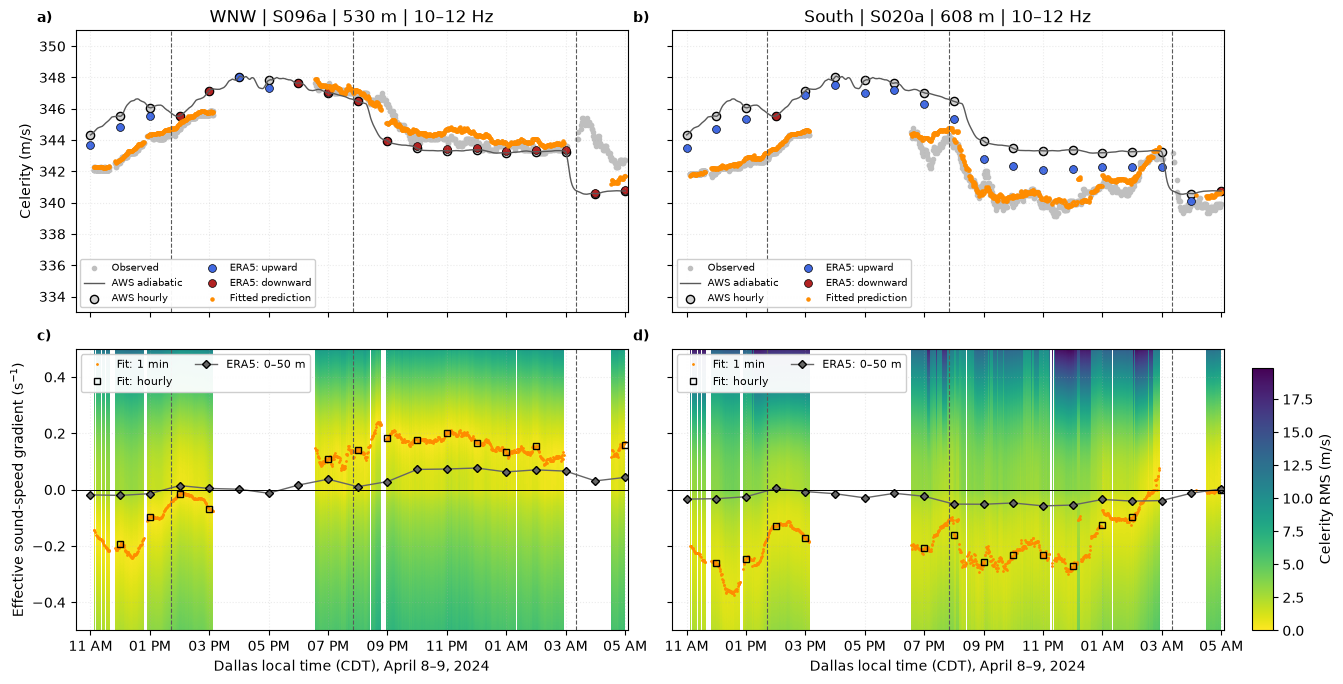

In [7]:
fig,axes=plt.subplots(2,2,figsize=(14,7.5),sharex=True,sharey='row')
fig.subplots_adjust(left=0.07,right=0.89,bottom=0.12,top=0.92,hspace=0.13,wspace=0.08)
rms_max=max(float(np.nanmax(s)) for s in rms_surfaces.values())
for col,group in enumerate(GROUPS):
    ax_c,ax_a=axes[:,col]
    receiver=REPRESENTATIVES[group]
    obs=load_metrics(receiver,START,END)
    obs=obs[obs.n_intvs >= 20]
    fit, hourly = fits[group], hourly_fits[group]
    base=era5[era5.group==group]
    ax_c.scatter(local_time(obs.evt0),obs.c_est,s=9,color='0.75',label='Observed')
    ax_c.plot(local_time(fit.t_utc),fit.c0_ad,color='0.35',lw=1,label='AWS adiabatic')
    ax_c.scatter(local_time(base.t_utc),base.c0_ad,s=35,edgecolor='k',facecolor='lightgrey',label='AWS hourly')
    for regime,colour,label in [('up','royalblue','ERA5: upward'),('down','firebrick','ERA5: downward')]:
        d=base[base.regime==regime]
        ax_c.scatter(local_time(d.t_utc),d.C_model,s=32,color=colour,edgecolor='k',lw=0.5,label=label)
    ax_c.scatter(local_time(fit.t_utc),models[group],s=5,color='darkorange',label='Fitted prediction')
    times=mdates.date2num(local_time(fit.t_utc).to_numpy())
    time_edges=np.r_[times-0.5/(24*60),times[-1]+0.5/(24*60)]
    a_edges=np.r_[A_GRID-A_STEP/2,A_GRID[-1]+A_STEP/2]
    mesh=ax_a.pcolormesh(time_edges,a_edges,np.ma.masked_invalid(rms_surfaces[group]),
                         cmap='viridis_r',vmin=0,vmax=rms_max,shading='flat',rasterized=True)
    ax_a.plot(local_time(fit.t_utc),fit.a_est_C,'.',color='darkorange',ms=2,label='Fit: 1 min')
    ax_a.plot(local_time(hourly.t_utc),hourly.a_est_C,'s',mfc='none',mec='black',ms=5,label='Fit: hourly')
    ax_a.plot(local_time(base.t_utc),base.a_E,'D-',color='0.4',mec='k',ms=4,lw=1,label='ERA5: 0–50 m')
    ax_a.axhline(0,color='k',lw=0.7)
    ax_a.set_ylim(-0.5,0.5)
    ax_c.set_ylim(333,351)
    ax_c.set_title(f'{group} | {receiver} | {geometry.loc[receiver,"dist"]:.0f} m | 10–12 Hz')
    ax_c.legend(loc='lower left',fontsize=7,ncol=2,framealpha=0.95)
    ax_a.legend(loc='upper left',fontsize=8,ncol=2,framealpha=0.95)
    ax_a.set_xlabel('Dallas local time (CDT), April 8–9, 2024')
axes[0,0].set_ylabel('Celerity (m/s)')
axes[1,0].set_ylabel('Effective sound-speed gradient (s$^{-1}$)')
time_axes(axes)
for ax,label in zip(axes.flat,'abcd'):
    ax.text(-0.07,1.03,label+')',transform=ax.transAxes,fontweight='bold')
cax=fig.add_axes([0.91,0.12,0.015,0.35])
fig.colorbar(mesh,cax=cax,label='Celerity RMS (m/s)')
plt.show()